# F29 — Le momentum est-il prévisible ?
**Projet de Bases de données et Data Science — Google Colab**

## Objectif
Prédire si le rendement mensuel du facteur momentum sera positif ou négatif à partir de ses rendements passés, puis comparer trois approches :
1. Signe du dernier mois (référence)
2. Régression logistique
3. Random Forest

> Les données sont téléchargées depuis la bibliothèque officielle de Kenneth R. French. Le notebook utilise un découpage chronologique pour éviter toute fuite d'information du futur.

## 1. Importation des bibliothèques

In [ ]:
import io
import zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

## 2. Téléchargement et lecture des données

Le fichier ZIP officiel contient une série mensuelle du facteur **Mom**. Les rendements sont généralement exprimés en pourcentage dans le fichier source.

In [ ]:
URL = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/F-F_Momentum_Factor_CSV.zip"

response = requests.get(URL, timeout=30)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    csv_name = next(name for name in z.namelist() if name.lower().endswith(".csv"))
    raw = z.read(csv_name).decode("latin1")

# Repérer automatiquement le début du tableau mensuel (lignes YYYYMM)
lines = raw.splitlines()
start = next(i for i, line in enumerate(lines)
             if line.strip()[:6].isdigit() and "," in line)

data = pd.read_csv(io.StringIO("\n".join(lines[start:])), header=None)
data = data.iloc[:, :2].copy()
data.columns = ["Date", "Mom"]

# Conserver uniquement les observations mensuelles YYYYMM
data["Date"] = data["Date"].astype(str).str.strip()
data = data[data["Date"].str.fullmatch(r"\d{6}")].copy()
data["Date"] = pd.to_datetime(data["Date"], format="%Y%m")
data["Mom"] = pd.to_numeric(data["Mom"], errors="coerce")
data = data.dropna().sort_values("Date").reset_index(drop=True)

# Conversion des pourcentages en rendements décimaux
data["Mom"] = data["Mom"] / 100

print("Dimensions :", data.shape)
print("Première date :", data["Date"].min().date())
print("Dernière date :", data["Date"].max().date())
display(data.head())

Dimensions : (1197, 2)
Première date : 1927-01-01
Dernière date : 2026-09-01


,Date,Mom
0,1927-01-01,0.0057
1,1927-02-01,-0.0151
2,1927-03-01,0.0352
3,1927-04-01,0.0435
4,1927-05-01,0.0278


## 3. Exploration visuelle

On observe l'évolution historique du facteur momentum. Les valeurs positives et négatives représentent les rendements mensuels du facteur.

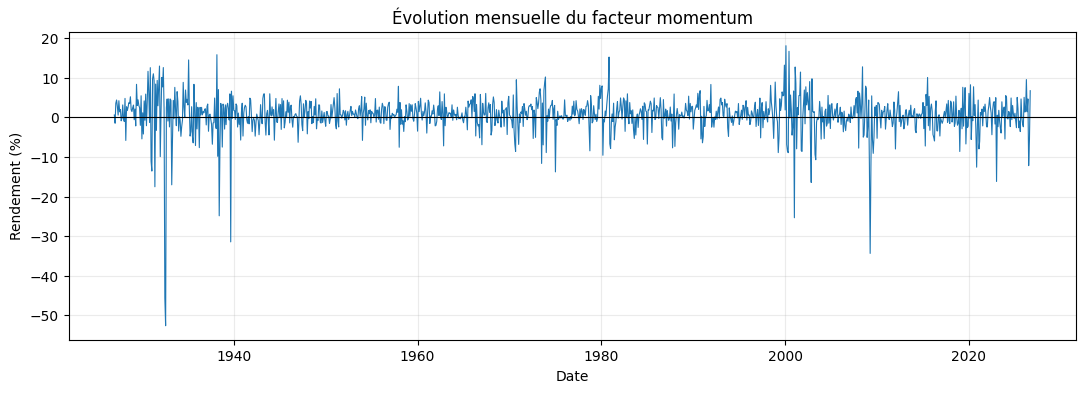

count    1197.0000
mean        0.0062
std         0.0470
min        -0.5261
25%        -0.0096
50%         0.0080
75%         0.0294
max         0.1805
Name: Mom, dtype: float64


In [ ]:
plt.figure(figsize=(13, 4))
plt.plot(data["Date"], data["Mom"] * 100, linewidth=0.8)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Évolution mensuelle du facteur momentum")
plt.xlabel("Date")
plt.ylabel("Rendement (%)")
plt.grid(alpha=0.25)
plt.show()

print(data["Mom"].describe().round(4))

## 4. Construction des variables explicatives et de la cible

Les variables explicatives sont les rendements passés sur plusieurs horizons :
- `mom_lag1` : rendement du mois précédent ;
- `mom_3m` : cumul des trois derniers mois ;
- `mom_6m` : cumul des six derniers mois ;
- `mom_12m` : cumul des douze derniers mois.

La cible vaut 1 si le rendement du mois suivant est positif, et 0 sinon. Pour éviter d'utiliser une information future, les variables sont décalées et la cible correspond au rendement du mois courant prédit à partir des mois précédents.

In [ ]:
df = data.copy()

# Rendements passés cumulés, calculés à partir du mois précédent
df["mom_lag1"] = df["Mom"].shift(1)
df["mom_3m"] = (1 + df["Mom"]).rolling(3).apply(np.prod, raw=True).shift(1) - 1
df["mom_6m"] = (1 + df["Mom"]).rolling(6).apply(np.prod, raw=True).shift(1) - 1
df["mom_12m"] = (1 + df["Mom"]).rolling(12).apply(np.prod, raw=True).shift(1) - 1

# Cible : rendement du mois courant (connu à la fin du mois) positif ou non
df["target"] = (df["Mom"] > 0).astype(int)

df = df.dropna().reset_index(drop=True)

features = ["mom_lag1", "mom_3m", "mom_6m", "mom_12m"]
X = df[features]
y = df["target"]

print("Nombre d'observations après prétraitement :", len(df))
print("\nRépartition de la cible (0 = négatif ou nul, 1 = positif) :")
print(y.value_counts(normalize=True).rename("Proportion").round(3))
display(df[["Date"] + features + ["Mom", "target"]].head())

Nombre d'observations après prétraitement : 1185

Répartition de la cible (0 = négatif ou nul, 1 = positif) :
target
1    0.624
0    0.376
Name: Proportion, dtype: float64


,Date,mom_lag1,mom_3m,mom_6m,mom_12m,Mom,target
0,1928-01-01,0.0311,0.019470,0.097307,0.213258,-0.0045,0
1,1928-02-01,-0.0045,0.024099,0.048641,0.200953,-0.0107,0
2,1928-03-01,-0.0107,0.015477,0.023501,0.206318,0.0475,1
3,1928-04-01,0.0475,0.031628,0.051714,0.220651,-0.0585,0
4,1928-05-01,-0.0585,-0.024331,-0.000818,0.101335,0.0264,1


## 5. Découpage chronologique

Les premières 80 % des observations servent à l'entraînement et les 20 % les plus récentes au test. On ne mélange pas les dates.

In [ ]:
split = int(len(df) * 0.80)

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]
test_dates = df["Date"].iloc[split:]

print("Période entraînement :", df["Date"].iloc[0].date(), "à", df["Date"].iloc[split-1].date())
print("Période test :", df["Date"].iloc[split].date(), "à", df["Date"].iloc[-1].date())
print("Observations entraînement :", len(X_train))
print("Observations test :", len(X_test))

Période entraînement : 1928-01-01 à 2006-12-01
Période test : 2007-01-01 à 2026-09-01
Observations entraînement : 948
Observations test : 237


## 6. Entraînement des modèles

Le modèle de référence prédit que le signe du mois suivant sera identique à celui du dernier mois observé. Les deux autres modèles apprennent une relation à partir de plusieurs horizons historiques.

In [ ]:
# Modèle de référence : signe du dernier mois
baseline_pred = (X_test["mom_lag1"] > 0).astype(int)

# Régression logistique : imputation + standardisation + classification
log_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42))
])
log_model.fit(X_train, y_train)
log_pred = log_model.predict(X_test)

# Forêt aléatoire
rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300, max_depth=4, min_samples_leaf=8,
        class_weight="balanced", random_state=42
    ))
])
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

## 7. Évaluation et comparaison

L'exactitude mesure la proportion de prédictions correctes. La précision, le rappel et le F1-score complètent l'analyse, notamment si les deux classes sont déséquilibrées.

,Accuracy,Precision,Recall,F1-score
Modèle,,,,
Signe du dernier mois (référence),0.477,0.544,0.544,0.544
Régression logistique,0.578,0.610,0.735,0.667
Random Forest,0.532,0.583,0.647,0.613


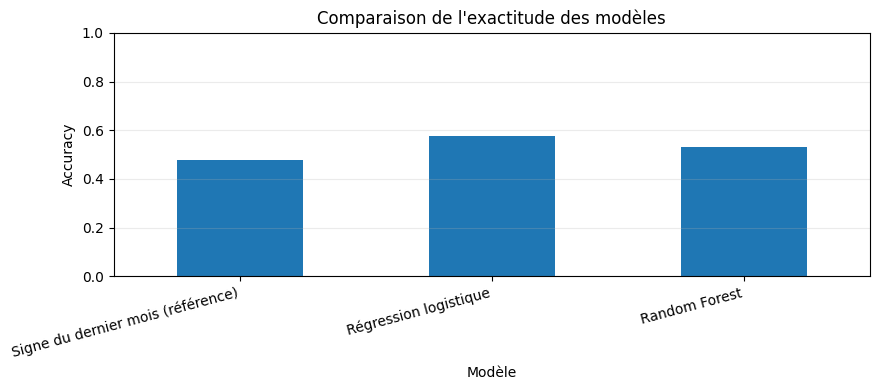

In [ ]:
predictions = {
    "Signe du dernier mois (référence)": baseline_pred,
    "Régression logistique": log_pred,
    "Random Forest": rf_pred
}

results = []
for name, pred in predictions.items():
    results.append({
        "Modèle": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0)
    })

results_df = pd.DataFrame(results).set_index("Modèle")
display(results_df.round(3))

ax = results_df["Accuracy"].plot(kind="bar", figsize=(9, 4), ylim=(0, 1),
                                  title="Comparaison de l'exactitude des modèles")
ax.set_ylabel("Accuracy")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## 8. Matrices de confusion

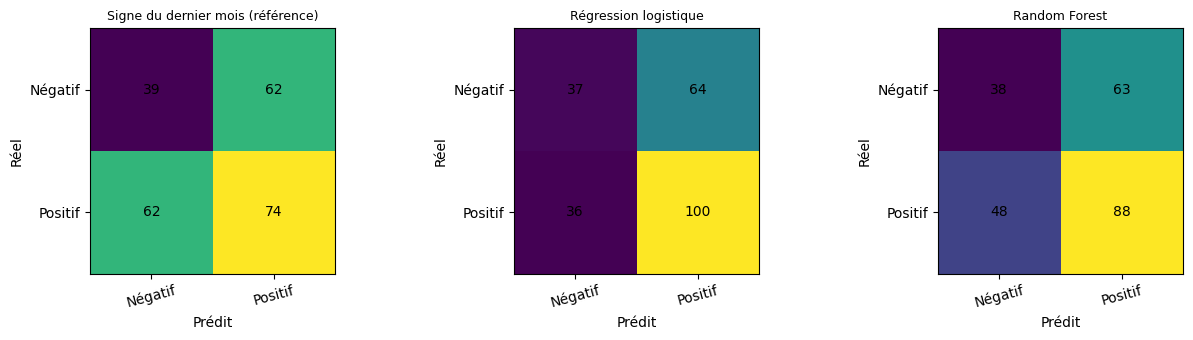

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    ax.imshow(cm)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("Prédit")
    ax.set_ylabel("Réel")
    ax.set_xticks([0, 1], ["Négatif", "Positif"], rotation=15)
    ax.set_yticks([0, 1], ["Négatif", "Positif"])
    for (i, j), value in np.ndenumerate(cm):
        ax.text(j, i, str(value), ha="center", va="center")
plt.tight_layout()
plt.show()

## 9. Simulation simple d'une stratégie

Règle testée : investir sur le facteur momentum si le modèle prédit un rendement positif, sinon rester en liquidités. Le rendement de la stratégie est diminué d'un coût de transaction forfaitaire lorsque la position change.

**Hypothèse pédagogique :** coût de 0,10 % par changement de position. Ce coût est un paramètre à justifier et peut être modifié.

,Rendement cumulé net (%),Rendement mensuel moyen net (%),Volatilité mensuelle (%),Drawdown maximal (%),Nombre de changements de position
Stratégie,,,,,
Signe du dernier mois (référence),-17.34,-0.03,3.14,-41.39,124
Régression logistique,9.78,0.12,3.83,-56.52,55
Random Forest,-7.36,0.06,4.03,-47.99,81


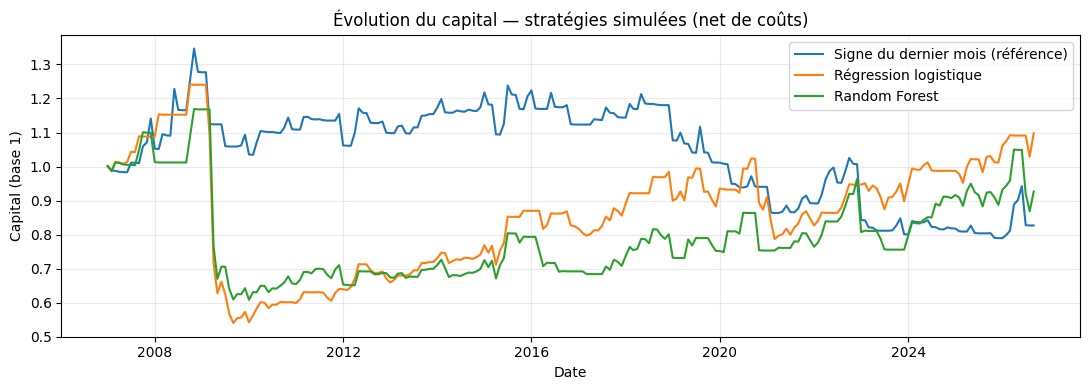

In [ ]:
COST_PER_TURNOVER = 0.001  # 0,10 % par unité de turnover

def simulate_strategy(pred, actual_returns, cost=COST_PER_TURNOVER):
    position = np.asarray(pred, dtype=float)  # 1 investi, 0 en liquidités
    returns = np.asarray(actual_returns, dtype=float)
    previous_position = np.r_[0.0, position[:-1]]
    turnover = np.abs(position - previous_position)
    net_returns = position * returns - cost * turnover
    equity = (1 + net_returns).cumprod()
    return net_returns, equity, turnover

actual_test_returns = df["Mom"].iloc[split:].to_numpy()

strategy_rows = []
strategy_curves = {}
for name, pred in predictions.items():
    net_ret, equity, turnover = simulate_strategy(pred, actual_test_returns)
    strategy_curves[name] = equity
    strategy_rows.append({
        "Stratégie": name,
        "Rendement cumulé net (%)": (equity[-1] - 1) * 100,
        "Rendement mensuel moyen net (%)": net_ret.mean() * 100,
        "Volatilité mensuelle (%)": net_ret.std(ddof=1) * 100,
        "Drawdown maximal (%)": ((equity / np.maximum.accumulate(equity)) - 1).min() * 100,
        "Nombre de changements de position": int(turnover.sum())
    })

strategy_results = pd.DataFrame(strategy_rows).set_index("Stratégie")
display(strategy_results.round(2))

plt.figure(figsize=(11, 4))
for name, equity in strategy_curves.items():
    plt.plot(test_dates, equity, label=name)
plt.title("Évolution du capital — stratégies simulées (net de coûts)")
plt.xlabel("Date")
plt.ylabel("Capital (base 1)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 10. Analyse du risque de crash

Une bonne exactitude moyenne ne garantit pas une stratégie rentable. Il faut examiner les mois les plus défavorables et les pertes extrêmes. Le tableau ci-dessous présente les cinq pires rendements du facteur pendant la période de test.

In [ ]:
worst_months = df.iloc[split:][["Date", "Mom"]].copy()
worst_months["Rendement (%)"] = worst_months["Mom"] * 100
display(worst_months.nsmallest(5, "Mom")[["Date", "Rendement (%)"]])

# Comparaison : mois positifs/négatifs et rendement moyen
print("Part des mois positifs dans le test :", round(y_test.mean() * 100, 2), "%")
print("Pire rendement mensuel du test :", round(actual_test_returns.min() * 100, 2), "%")

,Date,Rendement (%)
975,2009-04-01,-34.36
1140,2023-01-01,-16.21
1114,2020-11-01,-12.60
976,2009-05-01,-12.54
1182,2026-07-01,-12.21


Part des mois positifs dans le test : 57.38 %
Pire rendement mensuel du test : -34.36 %


## 11. Conclusion automatique à compléter après exécution

Les résultats affichés permettent de répondre à la problématique. Il faut identifier le modèle qui dépasse — ou non — la référence, puis vérifier si cet avantage se traduit par une meilleure performance nette de coûts.

**Conclusion à rédiger à partir des résultats obtenus :**
- Si les modèles dépassent peu ou pas la référence, le pouvoir prédictif du momentum est limité sur la période testée.
- Si l'exactitude s'améliore mais que la stratégie perd de l'argent, la qualité statistique des prédictions ne suffit pas à créer une stratégie rentable.
- Les crashes du momentum rappellent qu'il faut étudier les pertes extrêmes et le drawdown, pas seulement l'accuracy.

**Limites :** une seule série de facteur, une seule période de test, des paramètres de modèles simplifiés et une hypothèse de coûts. Les résultats historiques ne garantissent pas les performances futures.

## 12. Export des résultats

Cette cellule permet de télécharger les tableaux de résultats depuis Google Colab.

In [ ]:
results_df.to_csv("comparaison_modeles.csv")
strategy_results.to_csv("performance_strategies.csv")

from google.colab import files
files.download("comparaison_modeles.csv")
files.download("performance_strategies.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>